# Tratamento de Dados Ausentes: Mecanismos de Ausência

O preenchimento (imputação) de dados consiste em substituir os valores ausentes (`NaN` / `NA`) por estimativas estatisticamente plausíveis.

Porém, antes de escrever qualquer linha de código, devemos responder: **"Por que este dado está faltando?"**. A validade da sua imputação depende inteiramente do mecanismo de ausência. A teoria estatística distingue três mecanismos principais:

---

## 1. MCAR (Missing Completely at Random)
**"Ausência Completamente Aleatória"**

* **O Cenário:** A ausência do dado é um acidente puro. Não tem relação com o valor da variável em si, nem com outras variáveis do banco de dados.
* **Exemplo:** Um pesquisador derrubou café em alguns questionários aleatórios, tornando a resposta ilegível. Ou um sensor falhou por falta de bateria em momentos aleatórios.
* **Consequência Prática:** É o cenário dos sonhos (e o mais raro).
    * **Pode remover linhas?** Sim. Remover os dados não introduz viés (bias), apenas reduz o tamanho da amostra.
    * **Imputação:** Métodos simples (Média, Mediana, Moda) funcionam razoavelmente bem aqui.

## 2. MAR (Missing at Random)
**"Ausência Aleatória (Condicional)"**

* **O Cenário:** A probabilidade de o dado faltar depende de **outras informações que nós temos** no dataset, mas não do valor que falta em si.
* **Exemplo:** Em uma pesquisa de saúde, homens (variável observada `Sexo`) são menos propensos a responder perguntas sobre "Tristeza" do que mulheres.
    * *Nota:* Se separarmos apenas os homens, a ausência é aleatória dentro desse grupo.
* **Consequência Prática:** É o cenário mais comum em Ciência de Dados.
    * **Pode remover linhas?** **evitar** Se você remover as linhas com dados faltantes, você removerá desproporcionalmente mais homens do que mulheres, enviesando seu modelo demográfico, neste caso.
    * **Imputação:** Exige métodos que olhem para as correlações. Usar tendencias centrais em  geral não é recomendado. O ideal é usar imputação baseada em modelos (KNN Imputer, MICE/Iterative Imputer) que usam a variável `Sexo` para prever a `Tristeza`.

## 3. MNAR (Missing Not at Random)
**"Ausência Não Aleatória"**

* **O Cenário:** O pior casp. A ausência está ligada ao próprio valor que deveria estar ali. O dado falta *porque* ele tem um valor específico.
* **Exemplo:**
    * **Renda:** Pessoas com salários muito altos recusam-se a responder.
    * **Sensores:** Um termômetro para de registrar dados quando a temperatura sobe acima de 100°C (o sensor falha). O `NaN` significa "Muito Quente".
* **Consequência Prática:**
    * **Imputação:** Imputar a média aqui é desastroso (você vai subestimar a renda ou a temperatura).
    * **Estratégia:** Frequentemente, a melhor saída não é tentar adivinhar o número, mas sim **sinalizar a ausência**. Criar uma nova coluna binária `Ausente` (1 ou 0) pode ajudar o modelo a aprender que aquele padrão de falta de informação é importante.

---

### Resumo para Decisão, mas cada caso deve ser analisado, não é uma regra esta tebela.

| Mecanismo | O dado falta por quê? | Risco de Viés | Estratégia Sugerida |
| :--- | :--- | :--- | :--- |
| **MCAR** | Azar / Acaso | Baixo | Remoção ou Média/Mediana Simples |
| **MAR** | Depende de outros dados | Médio | Imputação Multivariada (KNN, MICE) |
| **MNAR** | Depende do valor oculto | Alto (Crítico) | Flag de Ausência ou Modelagem Específica |


---
### Modelos e suas operações com dados ausentes: [Scikitlearn](https://scikit-learn.org/stable/modules/impute.html)

# Técnicas Básicas de Imputação (Univariadas)

As técnicas univariadas são aquelas que olham para a coluna com dados faltantes isoladamente. Elas não buscam correlações com outras colunas para tentar "adivinhar" o valor. São rápidas, computacionalmente baratas, mas podem ser simplistas.

## 1. Estratégias de Remoção (Deletion)

Às vezes, a melhor imputação é não imputar.

### A. Remoção de Linhas (Listwise Deletion)
Consiste em excluir qualquer amostra (linha) que contenha pelo menos um valor ausente.
* **Vantagem:** Não cria dados artificiais. Mantém a "pureza" dos dados observados.
* **Quando usar:**
    1.  Temos certeza de que o mecanismo é **MCAR** (aleatório).
    2.  O volume de dados é grande o suficiente para suportar a perda.
    3.  A fração de linhas perdidas é pequena (ex: < 5%).
* **Risco:** Se não for MCAR, você introduz viés severo (ex: exclui todos os clientes de baixa renda que não informaram salário).

### B. Remoção de Colunas (Dropping Features)
Consiste em descartar inteiramente a variável (coluna) do dataset.
.
* **Contexto de Negócio:** Cuidado! Às vezes, uma coluna com 90% de nulos é vital. Exemplo: `Data_Falecimento`. 99% será nulo (pessoas vivas), mas quando preenchido, é a informação mais importante para uma Seguradora.
* **Decisão:** Se a coluna não for crítica para o negócio e tiver muitos dados ausente(**> 60%**), descarte-a para reduzir ruído. levar em conta o modelo que vai ser empregado.

---

## 2. Imputação por Tendência Central (Simple Imputation)

Substituímos o NAN por um valor estatístico representativo daquela coluna.

### A. Média (Mean)
* **Uso:** Apenas para dados numéricos com **Distribuição Simétrica** (Curva Normal).
* **Problema:** É extremamente sensível a *outliers*. Um único valor grande puxa a média para cima, distorcendo a imputação.
* **Efeito Colateral:** Reduz artificialmente a variância dos dados (cria um "pico" na tendencia central).



### B. Mediana (Median)
* **Uso:** Para dados numéricos com **Distribuição Assimétrica** ou presença de **Outliers**.
* **Vantagem:** É robusta. O valor elevado não afeta a mediana de um grupo de salários normais.
* **Recomendação:** Na dúvida entre média e mediana, **escolha a mediana**. É mais seguro para a maioria dos algoritmos.

### C. Moda (Mode)
* **Uso:** Padrão  para **Dados Categóricos** (Nominais ou Ordinais).
* **Ação:** Preenche com a categoria mais frequente (ex: "Solteiro").
* **Uso Numérico:** Pode ser usado em dados numéricos discretos com poucos valores únicos (ex: número de filhos).


In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

# Criando um DataFrame de exemplo
data = {'idade': [25, 28, np.nan, 35, 32, np.nan, 40],
        'salario': [5000, 5400, 8700, np.nan, 6000, 5800, 6200],
        'cidade': ['SP', 'RJ', 'SP', 'BH', np.nan, 'SP', 'RJ']}
df = pd.DataFrame(data)
print("DataFrame Original:")
print(df)

# Removendo as linhas:
print("\nDataFrame Com remoção de linhas:")
print(df.dropna())

# Imputação por Mediana para 'salario' (robusto a outliers)
imputer_mediana = SimpleImputer(strategy='median')
df['salario'] = imputer_mediana.fit_transform(df[['salario']])

# Imputação por Média para 'idade'
imputer_media = SimpleImputer(strategy='mean')
df['idade'] = imputer_media.fit_transform(df[['idade']])

# Imputação por Moda para 'cidade' (categórico)
imputer_moda = SimpleImputer(strategy='most_frequent')
df['cidade'] = imputer_moda.fit_transform(df[['cidade']])[:, 0]

print("\nDataFrame Imputado:")
print(df)

DataFrame Original:
   idade  salario cidade
0   25.0   5000.0     SP
1   28.0   5400.0     RJ
2    NaN   8700.0     SP
3   35.0      NaN     BH
4   32.0   6000.0    NaN
5    NaN   5800.0     SP
6   40.0   6200.0     RJ

DataFrame Com remoção de linhas:
   idade  salario cidade
0   25.0   5000.0     SP
1   28.0   5400.0     RJ
6   40.0   6200.0     RJ

DataFrame Imputado:
   idade  salario cidade
0   25.0   5000.0     SP
1   28.0   5400.0     RJ
2   32.0   8700.0     SP
3   35.0   5900.0     BH
4   32.0   6000.0     SP
5   32.0   5800.0     SP
6   40.0   6200.0     RJ


##Imputação Multivariada

Diferente da imputação univariada (que olha apenas para a própria coluna), a imputação multivariada utiliza as **outras colunas** do dataset para estimar o valor ausente.

A lógica é tratar o dado faltante como um problema de **Predição**:
1.  As linhas com dados completos viram o **Conjunto de Treino**.
2.  A coluna com dados ausentes vira o **Target (Y)**.
3.  As outras colunas viram as **Features (X)**.

---

## 1. KNN Imputer (Tribo dos Analogistas)
**"Diga-me com quem andas e te direi quem és."**

Este método utiliza a distância geométrica para encontrar os "vizinhos" mais parecidos com a amostra que tem o dado faltante.

* **Como funciona:**
    1.  O algoritmo encontra as 'K' linhas mais parecidas com a linha que tem o `NaN` (baseado nas colunas que não estão vazias).
    2.  O valor imputado é a média (ou média ponderada pela distância) dos valores desses vizinhos.
* **Pré-requisito Crítico:**  os dados precisam estar Escalonados antes de usar o KNN Imputer.
* **Ideal para:** Padrões locais e clusters.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer

# Criando um DataFrame onde as colunas são correlacionadas
data_knn = {'altura_cm': [180, 165, np.nan, 175, 190, 155],
            'peso_kg': [85, 62, 70, 75, np.nan, 55],
            'idade': [30, 25, 28, 29, 40, 22]}
df_knn = pd.DataFrame(data_knn)
print("\nDataFrame Original para KNN:")
print(df_knn)

# KNNImputer vai usar a correlação entre altura, peso e idade
# n_neighbors=2 significa que ele vai olhar para os 2 vizinhos mais próximos
imputer_knn = KNNImputer(n_neighbors=2,weights="distance")
df_imputado_knn = pd.DataFrame(imputer_knn.fit_transform(df_knn), columns=df_knn.columns)

print("\nDataFrame Imputado com KNN:")
print(df_imputado_knn)


DataFrame Original para KNN:
   altura_cm  peso_kg  idade
0      180.0     85.0     30
1      165.0     62.0     25
2        NaN     70.0     28
3      175.0     75.0     29
4      190.0      NaN     40
5      155.0     55.0     22

DataFrame Imputado com KNN:
    altura_cm    peso_kg  idade
0  180.000000  85.000000   30.0
1  165.000000  62.000000   25.0
2  171.262544  70.000000   28.0
3  175.000000  75.000000   29.0
4  190.000000  78.181818   40.0
5  155.000000  55.000000   22.0


##Iterative Imputer / MICE
**"Multivariate Imputation by Chained Equations"**

É a técnica padrão para dados tabulares. Ao invés de fazer apenas uma passada (como descrito no passo a passo anterior), ele faz isso de forma **cíclica**.

* **Como funciona (O Loop):**
    1.  Preenche todos os ausentes inicialmente com a média/mediana (chute inicial).
    2.  Para a Coluna A: Remove o chute inicial e usa as Colunas B, C e D para prever o valor real de A (usando Regressão Linear, Bayesiana ou Árvores).
    3.  Atualiza os valores de A.
    4.  Passa para a Coluna B: Usa A (já atualizado), C e D para prever B.
    5.  Repete esse ciclo várias vezes até que os valores se estabilizem (convergir).
* **Vantagem:** Captura relacionamentos complexos entre todas as variáveis simultaneamente.

In [ ]:
from sklearn.experimental import enable_iterative_imputer #necessario
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.ensemble import RandomForestRegressor

# Usando o mesmo df_knn
print("\nDataFrame Original para MICE:")
print(df_knn)

#  MODELO 1: RANDOM FOREST
rf_estimator = RandomForestRegressor(
    n_estimators=10,
    random_state=25,
    n_jobs=-1
)

imputer_mice_rf = IterativeImputer(estimator=rf_estimator, max_iter=10, random_state=25, initial_strategy="median")
df_imputado_mice_rf = pd.DataFrame(imputer_mice_rf.fit_transform(df_knn), columns=df_knn.columns)

# MODELO 2: LINEAR (BAYESIAN RIDGE)
linear_estimator = BayesianRidge()

imputer_mice_linear = IterativeImputer(estimator=linear_estimator, max_iter=10, random_state=25, initial_strategy="median")
df_imputado_mice_linear = pd.DataFrame(imputer_mice_linear.fit_transform(df_knn), columns=df_knn.columns)

# Exibição dos Resultados
print("\nDataFrame Imputado com MICE (Random Forest):")
print(df_imputado_mice_rf)

print("\nDataFrame Imputado com MICE (Linear/Bayesian):")
print(df_imputado_mice_linear)


DataFrame Original para MICE:
   altura_cm  peso_kg  idade
0      180.0     85.0     30
1      165.0     62.0     25
2        NaN     70.0     28
3      175.0     75.0     29
4      190.0      NaN     40
5      155.0     55.0     22

DataFrame Imputado com MICE (Random Forest):
   altura_cm  peso_kg  idade
0      180.0     85.0   30.0
1      165.0     62.0   25.0
2      177.5     70.0   28.0
3      175.0     75.0   29.0
4      190.0     82.5   40.0
5      155.0     55.0   22.0

DataFrame Imputado com MICE (Linear/Bayesian):
    altura_cm    peso_kg  idade
0  180.000000  85.000000   30.0
1  165.000000  62.000000   25.0
2  169.582847  70.000000   28.0
3  175.000000  75.000000   29.0
4  190.000000  95.173329   40.0
5  155.000000  55.000000   22.0


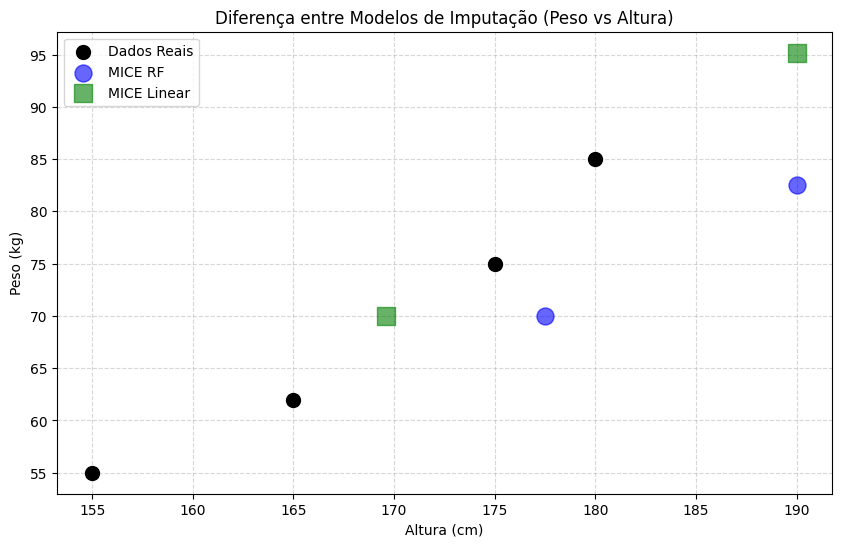

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# GERANDO O GRÁFICO
plt.figure(figsize=(10, 6))

# Dados Reais
mask_completo = df_knn.notna().all(axis=1)
plt.scatter(df_knn.loc[mask_completo, 'altura_cm'], df_knn.loc[mask_completo, 'peso_kg'],
            color='black', label='Dados Reais', s=100, zorder=5)

# Índices onde houve imputação
idx_h = 2 # Altura faltante
idx_w = 4 # Peso faltante


# Plotando MICE RF (Azul O)
plt.scatter([df_imputado_mice_rf.loc[idx_h, 'altura_cm'], df_imputado_mice_rf.loc[idx_w, 'altura_cm']],
            [df_imputado_mice_rf.loc[idx_h, 'peso_kg'], df_imputado_mice_rf.loc[idx_w, 'peso_kg']],
            color='blue', marker='o', s=150, label='MICE RF', alpha=0.6, zorder=6)

# Plotando MICE Linear (Verde S)
plt.scatter([df_imputado_mice_linear.loc[idx_h, 'altura_cm'], df_imputado_mice_linear.loc[idx_w, 'altura_cm']],
            [df_imputado_mice_linear.loc[idx_h, 'peso_kg'], df_imputado_mice_linear.loc[idx_w, 'peso_kg']],
            color='green', marker='s', s=150, label='MICE Linear', alpha=0.6, zorder=6)

# Estilização
plt.title('Diferença entre Modelos de Imputação (Peso vs Altura)')
plt.xlabel('Altura (cm)')
plt.ylabel('Peso (kg)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Como lidar no cenario de MNAR

Além das abordagens puramente estatísticas (Média, Mediana, KNN), existem situações onde precisamos ser mais criativos ou entender o negócio.

## Imputação com Indicador (Missing Indicator)
Esta técnica combina a imputação estatística com a criação de uma nova *feature*.

* **O Problema:** Ao preencher um `NaN` com a média, "escondemos" do modelo o fato de que aquele dado era originalmente desconhecido. Se a ausência não for aleatória (MNAR), perdemos informação valiosa.
* **A Solução:**
    1.  Preenchemos o valor numérico com a Mediana/Média.
    2.  Criamos uma nova coluna binária `Foi_Imputado` (1 = Sim, 0 = Não).



In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

# DataFrame de exemplo
data = {'idade': [25, 28, np.nan, 35, 32],
        'salario': [50000, np.nan, 52000, np.nan, 60000]}
df = pd.DataFrame(data)

print("DataFrame Original:")
print(df)

# Instanciando o imputer com a criação do indicador
imputer = SimpleImputer(strategy="constant",fill_value=-1, add_indicator=True)

# Aplicando o transformador
# O resultado é um array NumPy
dados_transformados = imputer.fit_transform(df)

# Para entender o resultado, vamos pegar os nomes das features
# A função get_feature_names_out() é para isso
nomes_features = imputer.get_feature_names_out(input_features=df.columns)

# Convertendo de volta para um DataFrame para melhor visualização
df_transformado = pd.DataFrame(dados_transformados, columns=nomes_features)

print("\nDataFrame Transformado (com Imputação + Flags):")
print(df_transformado)

DataFrame Original:
   idade  salario
0   25.0  50000.0
1   28.0      NaN
2    NaN  52000.0
3   35.0      NaN
4   32.0  60000.0

DataFrame Transformado (com Imputação + Flags):
   idade  salario  missingindicator_idade  missingindicator_salario
0   25.0  50000.0                     0.0                       0.0
1   28.0     -1.0                     0.0                       1.0
2   -1.0  52000.0                     1.0                       0.0
3   35.0     -1.0                     0.0                       1.0
4   32.0  60000.0                     0.0                       0.0


# imputação para serires temporais


Diferente de datasets tabulares comuns (como o Titanic ou Preços de Casas), onde a ordem das linhas não altera a estatística, em **Séries Temporais** a dependência temporal desempenha um papel central. O valor de hoje é fortemente influenciado pelo valor de ontem (*Autocorrelação*).

Portanto, usar a média global para preencher uma série temporal geralmente é um erro, pois destrói a tendência e a sazonalidade.

Abaixo, as 4 técnicas fundamentais para lidar com `NaN` no tempo.


## 1. LOCF (Last Observation Carried Forward)
**"Olhar para trás" / Forward Fill**

É a técnica mais intuitiva e segura contra vazamento de dados (*Data Leakage*). Assumimos que o estado atual permanece inalterado até que se prove o contrário.

* **Conceito:** Se o dado de hoje está faltando, repito o dado de ontem.
* **Uso ideal:** Preços de ativos financeiros (se não houve negociação, o preço se mantém), estoques, temperatura (em intervalos curtos).
* **Python:** `df.ffill()`

## 2. NOCB (Next Observation Carried Backward)
**"Olhar para frente" / Backward Fill**

Olhamos para o futuro para preencher o passado.

* **Conceito:** Se o dado de hoje falta, pego o dado de amanhã e trago para cá.
* **Uso ideal:** Limpeza de dados históricos para análise descritiva ou para preencher lacunas no *início* do dataset.
* **atenção:** Jamais use isso se o seu objetivo é **Previsão (Forecasting)**. Você estará ensinando ao modelo eventos que ainda não aconteceram.
* **Python:** `df.bfill()`

## 3. Interpolação Linear/ou de maior ordem
**"Ligar os pontos"**

Em vez de degraus (como no LOCF/NOCB), traçamos uma linha reta entre o último ponto válido e o próximo ponto válido.

* **Conceito:** Assume que a mudança entre dois pontos ocorre de forma gradual.
* **Uso ideal:** Fenômenos físicos ou contínuos (Temperatura, Nível de um reservatório, Crescimento populacional).
* **Não usar:** Em dados caóticos ou voláteis (Ações na bolsa), pois suaviza artificialmente a volatilidade.
* **Python:** `df.interpolate(method='linear')`

## 4. Imputação Sazonal e Média Móvel
**"A história se repete"**

Se os métodos anteriores olham para os vizinhos imediatos (ontem/amanhã), este método olha para o **ciclo**.


* **Técnica:** Preencher o valor ausente com a média do mesmo período em ciclos anteriores/posteriores.
* **Python:** Requer manipulação de datas (agrupamento por mês/dia/hora).





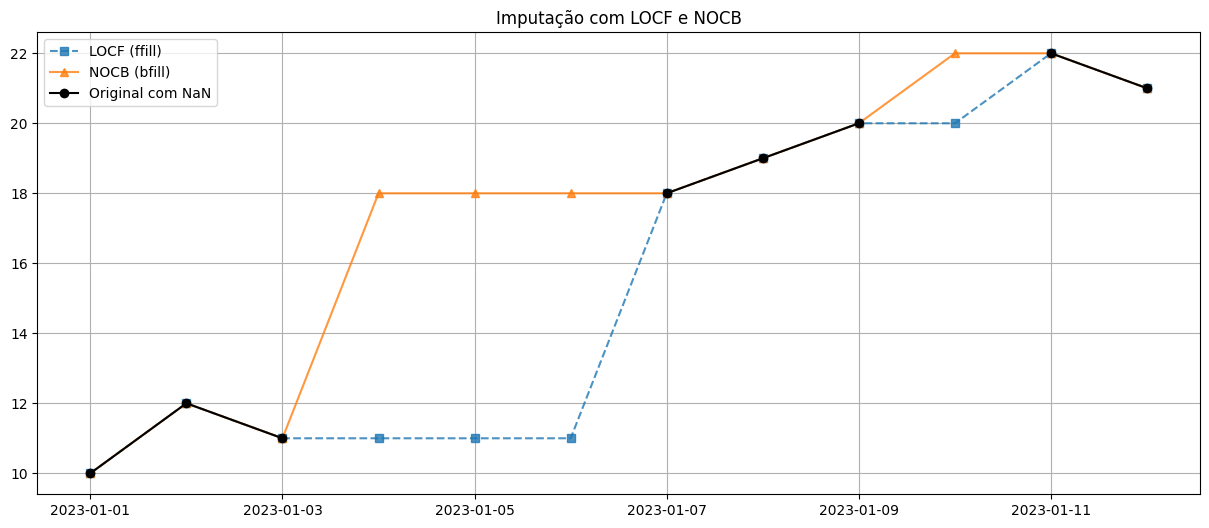

In [ ]:
import matplotlib.pyplot as plt

# Série temporal com dados ausentes
datas = pd.to_datetime(pd.date_range(start='2023-01-01', periods=12, freq='D'))
dados = [10, 12, 11, np.nan, np.nan, np.nan, 18, 19, 20, np.nan, 22, 21]
ts = pd.Series(dados, index=datas)

# Aplicando LOCF (forward fill)
#preencheo ultimo dado para frente
ts_ffill = ts.ffill()

# Aplicando NOCB (backward fill)
#preenche o primeiro dados apos a falha para traz
ts_bfill = ts.bfill()

# Visualização
plt.figure(figsize=(15, 6))

plt.plot(ts_ffill, 's--', label='LOCF (ffill)', alpha=0.8)
plt.plot(ts_bfill, '^-', label='NOCB (bfill)', alpha=0.8)
plt.plot(ts, 'o-', label='Original com NaN', color='black')
plt.title('Imputação com LOCF e NOCB')
plt.legend()
plt.grid(True)
plt.show()

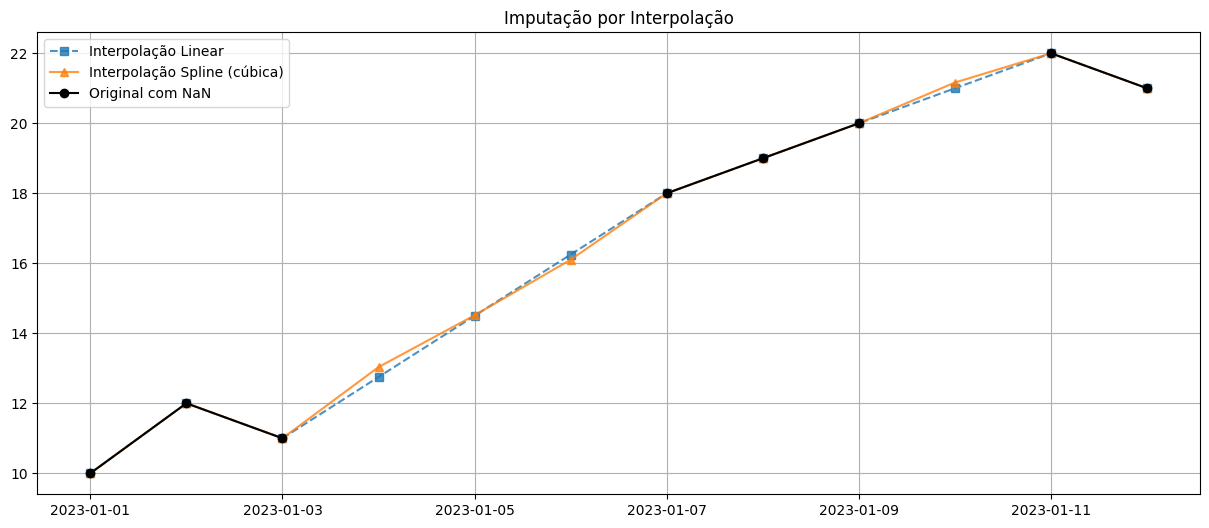

In [ ]:
 #Usando a mesma série 'ts' do exemplo anterior

# Interpolação Linear
ts_linear = ts.interpolate(method='linear')

# Interpolação Spline (requer SciPy)
# 'order=3' significa uma spline cúbica, uma escolha comum
ts_spline = ts.interpolate(method='spline', order=3)

# Visualização
plt.figure(figsize=(15, 6))

plt.plot(ts_linear, 's--', label='Interpolação Linear', alpha=0.8)
plt.plot(ts_spline, '^-', label='Interpolação Spline (cúbica)', alpha=0.8)
plt.plot(ts, 'o-', label='Original com NaN', color='black')
plt.title('Imputação por Interpolação')
plt.legend()
plt.grid(True)
plt.show()


Imputação com Média Móvel:
2024-01-01    10.0
2024-01-02    12.0
2024-01-03    14.0
2024-01-04    16.0
2024-01-05    18.0
2024-01-06    11.0
2024-01-07    13.0
2024-01-08    15.0
2024-01-09    17.0
2024-01-10    19.0
Freq: D, dtype: float64


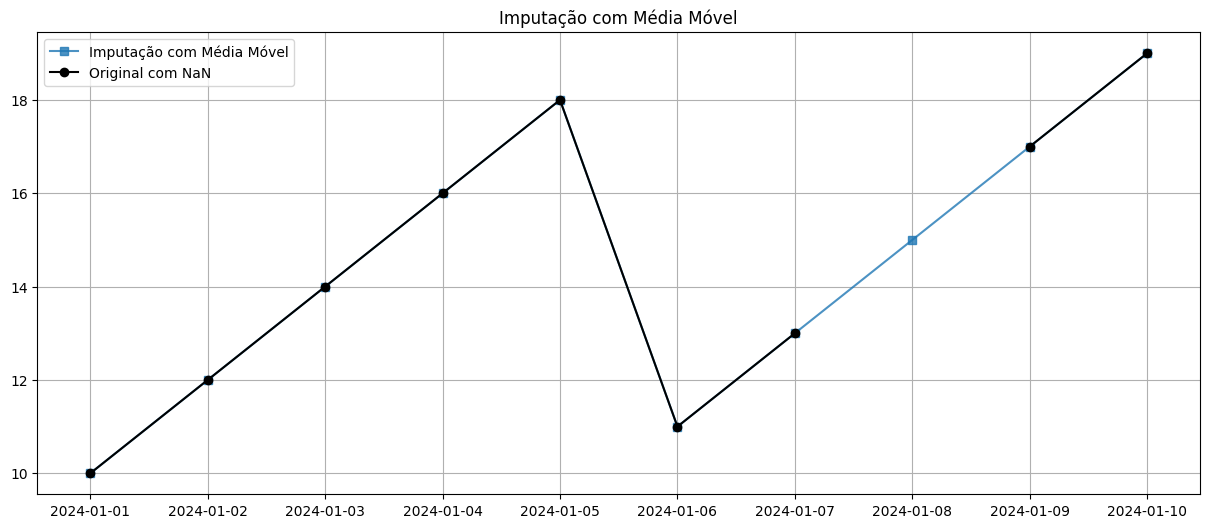

In [ ]:

# Usando o resultado da interpolação como um exemplo mais completo
ts_interpolada = pd.Series([10, 12, 14, 16, 18, 11, 13, np.nan, 17, 19],
                           index=pd.date_range('2024-01-01', periods=10))

# Imputar com a média da janela de 3 pontos centrada no NaN
# A média será calculada com os valores vizinhos (13 e 17)
ts_rolling = ts_interpolada.rolling(window=3, min_periods=1, center=True).mean()
ts_imputado_rolling = ts_interpolada.fillna(ts_rolling)

print("\nImputação com Média Móvel:")
print(ts_imputado_rolling)

# Visualização
plt.figure(figsize=(15, 6))
plt.plot(ts_imputado_rolling, 's-', label='Imputação com Média Móvel', alpha=0.8)
plt.plot(ts_interpolada, 'o-', label='Original com NaN', color='black')
plt.title('Imputação com Média Móvel')
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipython-input-3444507234.py:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  datas = pd.date_range(start='2024-03-04 00:00', periods=total_horas, freq='H')


Total de pontos: 168
Total de NaNs introduzidos: 24


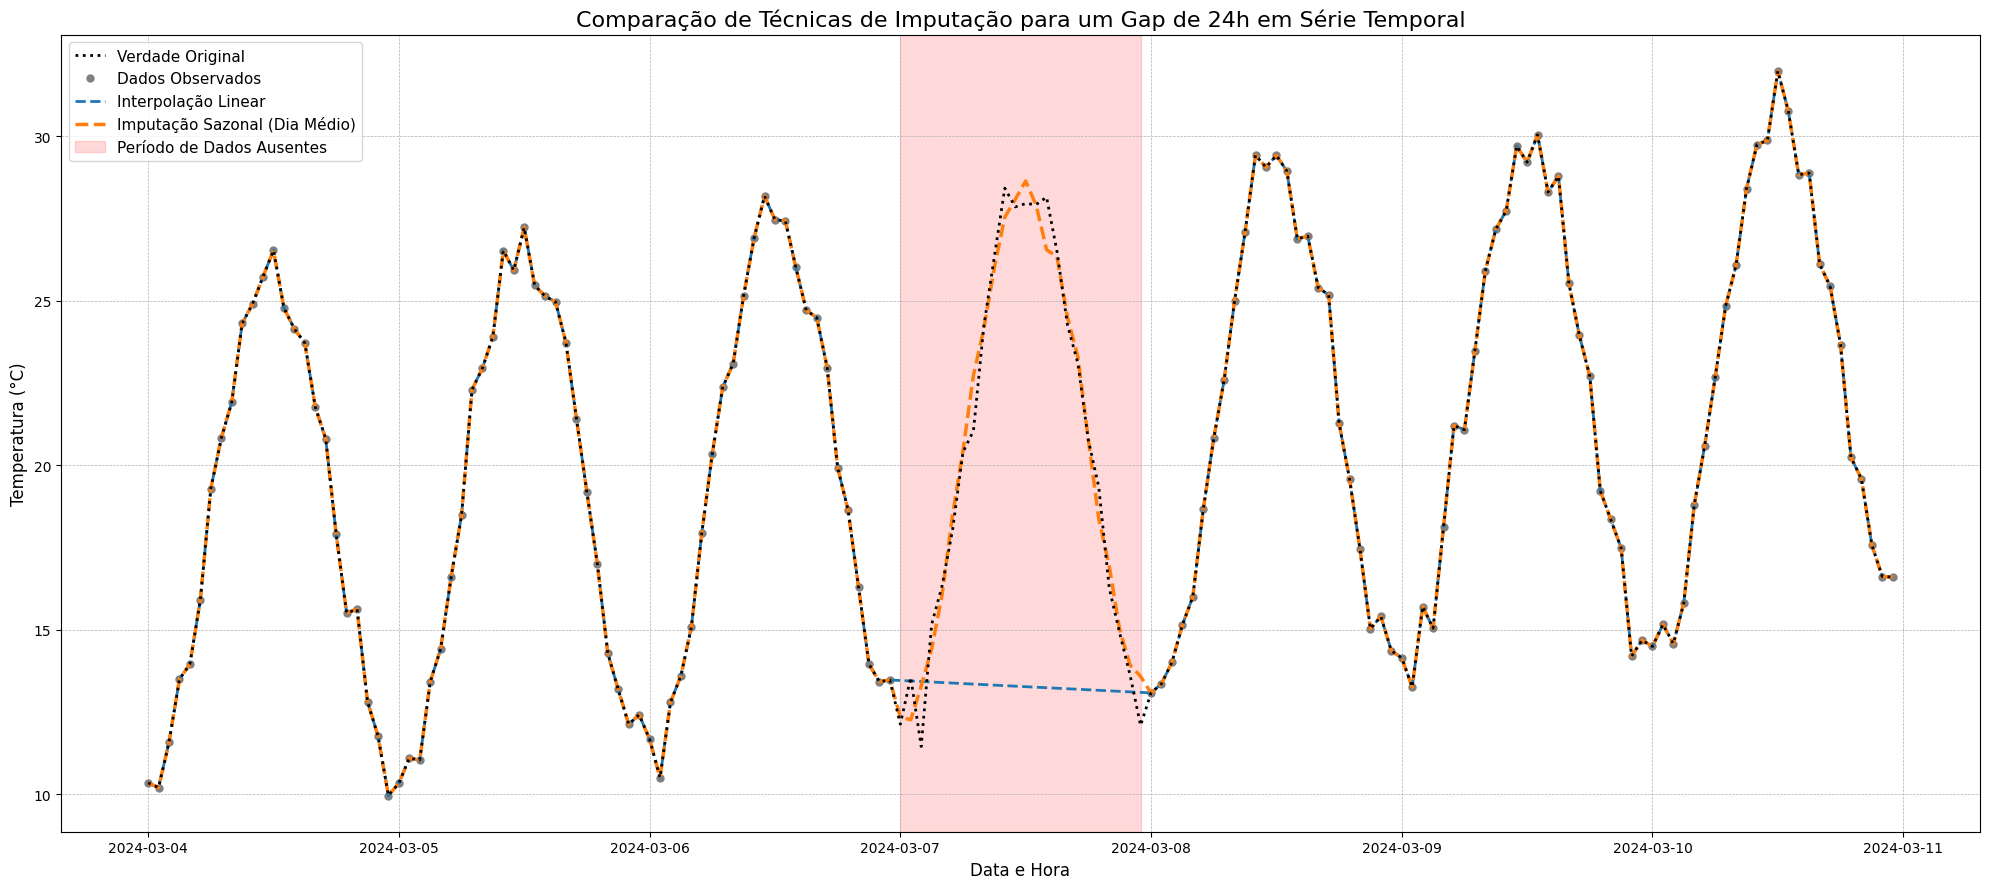

In [ ]:

# GERAÇÃO DE UMA SÉRIE TEMPORAL REALISTA

np.random.seed(42)
total_horas = 7 * 24  # 1 semana de dados horários
datas = pd.date_range(start='2024-03-04 00:00', periods=total_horas, freq='H')

# Componentes da série:
#Temperatura base e uma leve tendência de aquecimento durante a semana
temperatura_base = 18
tendencia_semanal = np.linspace(0, 5, total_horas)

#  Ciclo diário (sazonalidade de 24h) - usamos seno para simular
amplitude_diaria = 8
ciclo_diario = amplitude_diaria * np.sin(2 * np.pi * (datas.hour - 6) / 24)

# Ruído aleatório para tornar mais realista
ruido = np.random.normal(0, 0.7, total_horas)

# Série original completa
ts_original_completa = temperatura_base + tendencia_semanal + ciclo_diario + ruido
ts_original_completa = pd.Series(ts_original_completa, index=datas)

#
#INTRODUÇÃO DE UM GAP DE 24 HORAS
#
# Vamos remover os dados da quarta-feira (dia 4 do range)
ts_com_nan = ts_original_completa.copy()
ts_com_nan['2024-03-07':'2024-03-07 23:59'] = np.nan

print(f"Total de pontos: {len(ts_com_nan)}")
print(f"Total de NaNs introduzidos: {ts_com_nan.isnull().sum()}")


# APLICAÇÃO DAS TÉCNICAS DE IMPUTAÇÃO


# INTERPOLAÇÃO LINEAR ---

ts_linear = ts_com_nan.interpolate(method='linear')


# >>>>>>> IMPUTAÇÃO SAZONAL ("DIA MÉDIO")<<<<<<<<
# Preenche a hora ausente com a média daquela hora nos outros dias o mesmo processo pode se aplicar a qualquer frequencia, mes ano hora.....
# Calculamos o "perfil médio" de um dia.
perfil_dia_medio = ts_com_nan.groupby(ts_com_nan.index.hour).mean()
# Criamos uma série com os valores a serem imputados
imputacao_sazonal_valores = ts_com_nan.index.map(lambda x: perfil_dia_medio[x.hour])
ts_sazonal = ts_com_nan.fillna(pd.Series(imputacao_sazonal_valores, index=ts_com_nan.index))

#VISUALIZAÇÃO COMPARATIVA

fig, ax = plt.subplots(figsize=(20, 9))

# A "verdade": nossa série original completa
ax.plot(ts_original_completa.index, ts_original_completa.values,
        label='Verdade Original', color='black', linestyle=':', linewidth=2, zorder=10)

# Os pontos que temos e o gap
ax.plot(ts_com_nan.index, ts_com_nan.values, 'o',
        label='Dados Observados', color='gray', markersize=5)

# Resultados das imputações
ax.plot(ts_linear, label='Interpolação Linear', linestyle='--', linewidth=2)
ax.plot(ts_sazonal, label='Imputação Sazonal (Dia Médio)', linestyle='--', linewidth=2.5)


# Destacando a área do gap
gap_start = ts_com_nan.index[ts_com_nan.isnull()][0]
gap_end = ts_com_nan.index[ts_com_nan.isnull()][-1]
ax.axvspan(gap_start, gap_end, color='red', alpha=0.15, label='Período de Dados Ausentes')

ax.set_title('Comparação de Técnicas de Imputação para um Gap de 24h em Série Temporal', fontsize=16)
ax.set_xlabel('Data e Hora', fontsize=12)
ax.set_ylabel('Temperatura (°C)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

## Atividade

Desenvolva o preenchimento de falhas na serie temporal fornecida



In [ ]:
# URL do arquivo CSV
url = "https://gist.githubusercontent.com/Marcelo-BDiaz/b34092cbc11594185c01945737e03198/raw/fdc6fa2f36773fa267d2c542532dfa08be3d2628/Dados_meteorologicos.csv"

# Carregar o CSV,
df_meteorologicos = pd.read_csv()

# Renomear colunas
df_meteorologicos.columns = ['DATA', 'HORA', 'PRECIPITACAO',
                             'pressao', 'PRESSAO_MAX', 'PRESSAO_MIN',
                             'RADIACAO', 'temperatura', 'PONTO_ORVALHO',
                             'TEMP_MAX', 'TEMP_MIN', 'ORVALHO_MAX',
                             'ORVALHO_MIN', 'UMIDADE_MAX', 'UMIDADE_MIN',
                             'UMIDADE', 'VENTO_DIRECAO', 'VENTO_RAJADA',
                             'VENTO_VELOCIDADE', 'Unnamed']

# Selecionar colunas
df_selected = df_meteorologicos[['DATA', 'HORA', 'temperatura', 'RADIACAO', 'PRECIPITACAO', 'UMIDADE', 'VENTO_VELOCIDADE']]

# Combinar 'DATA' e 'HORA' e definir como índice
df_selected['datetime'] = pd.to_datetime(df_selected['DATA'] + ' ' + df_selected['HORA'])+pd.Timedelta(hours=-3)
df_selected = df_selected.set_index('datetime')
df_selected = df_selected.drop(columns=['DATA', 'HORA'])

# Cria a cópia para trabalhar
df_nan = df_selected.copy()

#vamos gerar algumas falhas temporais
# Usamos df_nan.index.dt.day para acessar o dia do mês a partir do índice
df_nan.loc[df_nan.index.day == 27, 'temperatura'] = np.nan #um dia inteiro
df_nan.loc['2018-09-03 15:00', 'temperatura'] = np.nan # uma hora
df_nan.loc['2018-09-02 03:00':'2018-09-02 06:00', 'temperatura'] = np.nan #um intervalo
df_nan.loc[pd.date_range(start='2018-09-07 03:00', periods=5, freq='h'), 'temperatura'] = np.nan # um intervalo

# Plotar a série temporal com a falha inserida
plt.figure(figsize=(15, 6))
plt.plot(df_selected.index, df_selected['temperatura'], color="red")
plt.plot(df_nan.index, df_nan['temperatura'], marker='.', linestyle='-')
plt.xlabel('Data e Hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()

### o resto é com vcs: gerar um função de imputação de dados como achar conviniente, pense em um modelo hibrido, use RMSE (Raiz do Erro Quadrático Médio ) para avaliar o preenchimento
# np.sqrt(mean_squared_error(y_true, y_pred))


## solução

/tmp/ipykernel_1242/1533774417.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_selected['datetime'] = pd.to_datetime(df_selected['DATA'] + ' ' + df_selected['HORA'])+pd.Timedelta(hours=-3)


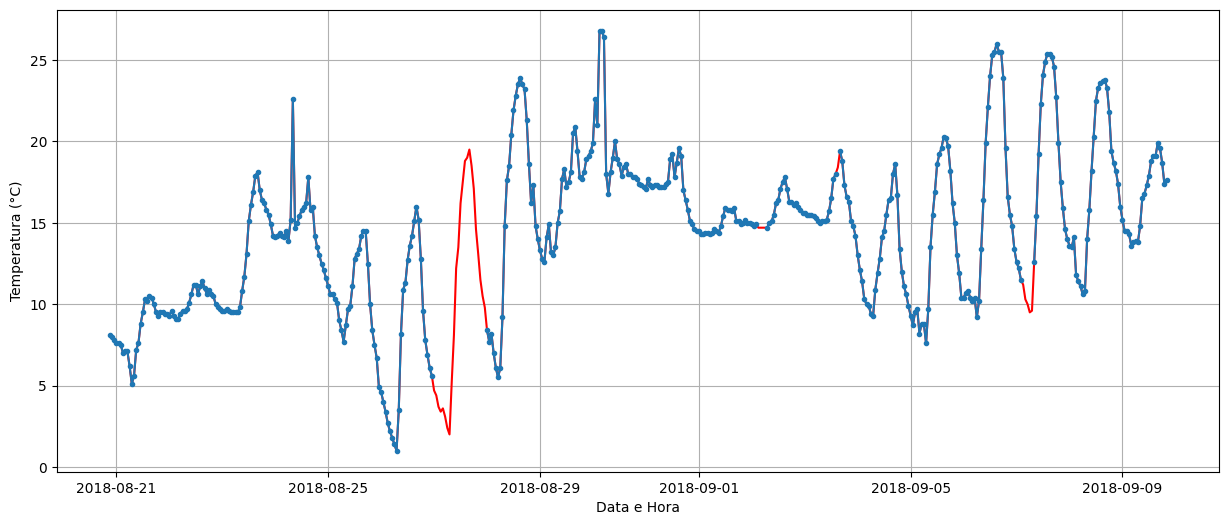

Preenchendo gaps de até 2 horas com interpolação linear...
Gaps longos detectados. Preparando features de tempo para o MICE...
Processo de imputação híbrida concluído.
4.460368609174879


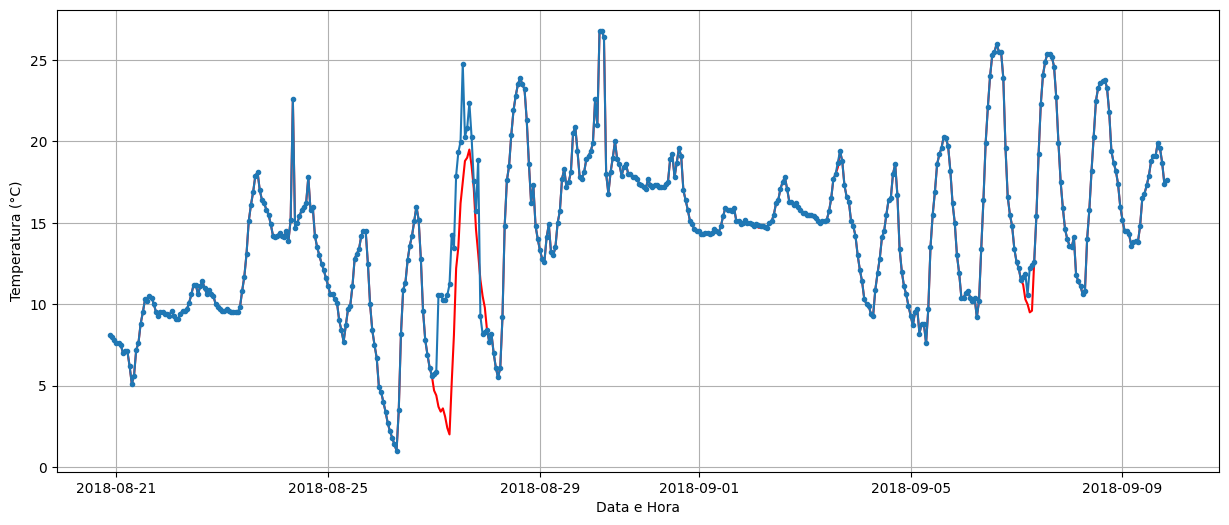

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# URL do arquivo CSV
url = "https://gist.githubusercontent.com/Marcelo-BDiaz/b34092cbc11594185c01945737e03198/raw/fdc6fa2f36773fa267d2c542532dfa08be3d2628/Dados_meteorologicos.csv"

# Carregar o CSV
df_meteorologicos = pd.read_csv(url, decimal=',', sep=";")

# Renomear colunas
df_meteorologicos.columns = ['DATA', 'HORA', 'PRECIPITACAO',
                             'pressao', 'PRESSAO_MAX', 'PRESSAO_MIN',
                             'RADIACAO', 'temperatura', 'PONTO_ORVALHO',
                             'TEMP_MAX', 'TEMP_MIN', 'ORVALHO_MAX',
                             'ORVALHO_MIN', 'UMIDADE_MAX', 'UMIDADE_MIN',
                             'UMIDADE', 'VENTO_DIRECAO', 'VENTO_RAJADA',
                             'VENTO_VELOCIDADE', 'Unnamed']

# Selecionar colunas
df_selected = df_meteorologicos[['DATA', 'HORA', 'temperatura', 'RADIACAO', 'PRECIPITACAO', 'UMIDADE', 'VENTO_VELOCIDADE']]

# Combinar 'DATA' e 'HORA' e definir como índice
df_selected['datetime'] = pd.to_datetime(df_selected['DATA'] + ' ' + df_selected['HORA'])+pd.Timedelta(hours=-3)
df_selected = df_selected.set_index('datetime')
df_selected = df_selected.drop(columns=['DATA', 'HORA'])

# Criar a cópia para trabalhar
df_nan = df_selected.copy()

# Usamos df_nan.index.dt.day para acessar o dia do mês a partir do índice
df_nan.loc[df_nan.index.day == 27, 'temperatura'] = np.nan #um dia inteiro
df_nan.loc['2018-09-03 15:00', 'temperatura'] = np.nan # uma hora
df_nan.loc['2018-09-02 03:00':'2018-09-02 06:00', 'temperatura'] = np.nan #um intervalo
df_nan.loc[pd.date_range(start='2018-09-07 03:00', periods=5, freq='h'), 'temperatura'] = np.nan # um intervalo

# Plotar a série temporal com a falha inserida
plt.figure(figsize=(15, 6))
plt.plot(df_selected.index, df_selected['temperatura'], color="red")
plt.plot(df_nan.index, df_nan['temperatura'], marker='.', linestyle='-')
plt.xlabel('Data e Hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()


from sklearn.experimental import enable_iterative_imputer  # Habilita o IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor  # Usaremos a Random Forest como nosso estimador
from sklearn.metrics import mean_squared_error


# A FUNÇÃO DE IMPUTAÇÃO HÍBRIDA

def imputacao_hibrida(df_com_falhas, coluna_alvo, features_base, limite_linear=2):

# df_com_falhas DataFrame com os dados ausentes.
# coluna_alvo (str): Nome da coluna a ser imputada (ex: 'temperatura').
# features_base (list): Lista de colunas a serem usadas pelo imputer.
# limite_linear (int): Tamanho máximo do gap a ser preenchido com interpolação linear.

    serie_imputada = df_com_falhas[coluna_alvo].copy()

    # --- ETAPA 1: Preencher falhas pequenas com Interpolação Linear ---
    print(f"Preenchendo gaps de até {limite_linear} horas com interpolação linear...")
    serie_imputada.interpolate(method='linear', limit=limite_linear, limit_direction='both', inplace=True)

    if not serie_imputada.isnull().any():
        print("Todos os gaps foram preenchidos com interpolação linear.")
        return serie_imputada

    # Preencher falhas longas restantes com MICE
    print("Gaps longos detectados. Preparando features de tempo para o MICE...")

    df_para_mice = df_com_falhas.copy()
    df_para_mice[coluna_alvo] = serie_imputada

    # Engenharia de Features de Tempo
    #df_para_mice['hora_sin'] = np.sin(2 * np.pi * df_para_mice.index.hour / 24)
    #df_para_mice['hora_cos'] = np.cos(2 * np.pi * df_para_mice.index.hour / 24)

    #features_completas = features_base + ['hora_sin', 'hora_cos']
    features_completas = features_base

    # O estimador RandomForest é poderoso para capturar relações não-lineares.
    # Usamos n_estimators=10 para ser mais rápido no exemplo.
    imputer_mice = IterativeImputer(
        estimator=RandomForestRegressor(n_estimators=100, random_state=42),
        max_iter=10,        # Número de rodadas de imputação
        random_state=42,
        max_value=40,       # Valores máximos e mínimos para evitar previsões absurdas
        min_value=0
    )


    dados_imputados = imputer_mice.fit_transform(df_para_mice[features_completas])


    df_imputado_final = pd.DataFrame(dados_imputados, columns=features_completas, index=df_com_falhas.index)

    print("Processo de imputação híbrida concluído.")
    return df_imputado_final[coluna_alvo]



# usando a função

# Definindo as colunas para o modelo KNN
colunas_base = ['temperatura', 'UMIDADE', 'RADIACAO']

# Chamando a função de imputação híbrida
serie_resultado = imputacao_hibrida(
    df_com_falhas=df_nan,
    coluna_alvo='temperatura',
    features_base=colunas_base,
    limite_linear=2  # Define que gaps de até 2h serão lineares
)

mascara_falhas = df_nan['temperatura'].isnull()

y_true = df_selected.loc[mascara_falhas, "temperatura"]
y_pred = serie_resultado.loc[mascara_falhas]
print(np.sqrt(mean_squared_error(y_true, y_pred)))



plt.figure(figsize=(15, 6))
plt.plot(df_selected.index, df_selected['temperatura'], color="red")
plt.plot(serie_resultado.index, serie_resultado.values, marker='.', linestyle='-')
plt.xlabel('Data e Hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()

/tmp/ipython-input-3622948402.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_selected['datetime'] = pd.to_datetime(df_selected['DATA'] + ' ' + df_selected['HORA'])+pd.Timedelta(hours=-3)


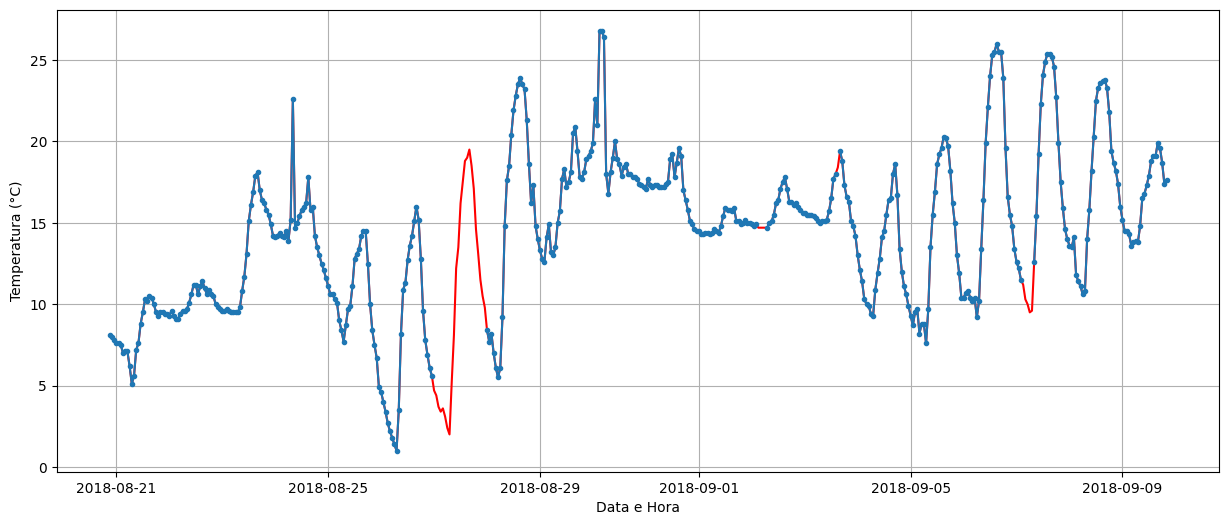

Preenchendo gaps de até 2 horas com interpolação linear...
Processo de imputação concluído.
1.7390397771198989


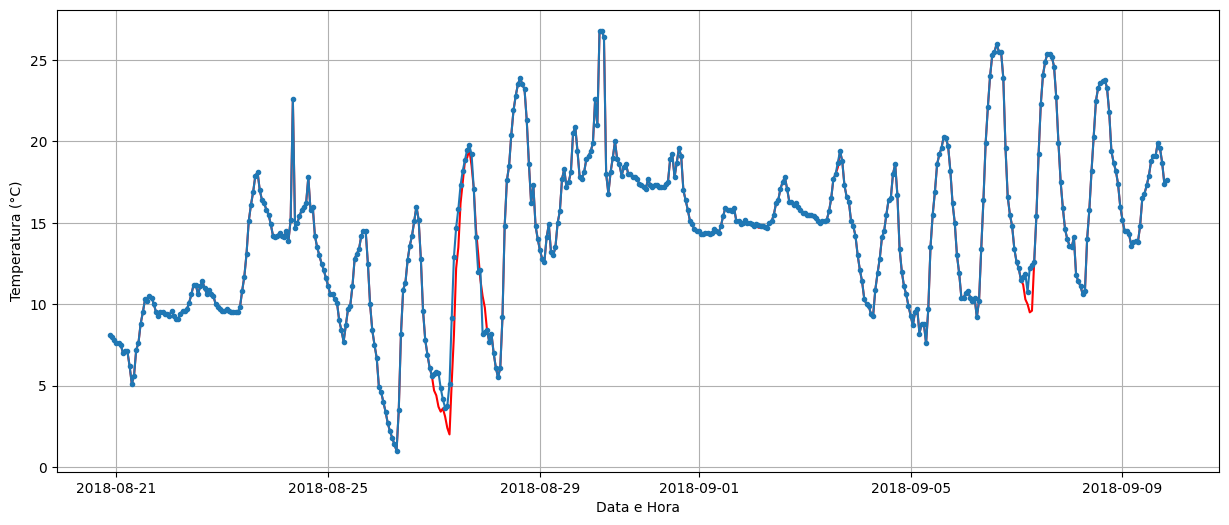

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# URL do arquivo CSV
url = "https://gist.githubusercontent.com/Marcelo-BDiaz/b34092cbc11594185c01945737e03198/raw/fdc6fa2f36773fa267d2c542532dfa08be3d2628/Dados_meteorologicos.csv"

# Carregar o CSV
df_meteorologicos = pd.read_csv(url, decimal=',', sep=";")

# Renomear colunas
df_meteorologicos.columns = ['DATA', 'HORA', 'PRECIPITACAO',
                             'pressao', 'PRESSAO_MAX', 'PRESSAO_MIN',
                             'RADIACAO', 'temperatura', 'PONTO_ORVALHO',
                             'TEMP_MAX', 'TEMP_MIN', 'ORVALHO_MAX',
                             'ORVALHO_MIN', 'UMIDADE_MAX', 'UMIDADE_MIN',
                             'UMIDADE', 'VENTO_DIRECAO', 'VENTO_RAJADA',
                             'VENTO_VELOCIDADE', 'Unnamed']

# Selecionar colunas
df_selected = df_meteorologicos[['DATA', 'HORA', 'temperatura', 'RADIACAO', 'PRECIPITACAO', 'UMIDADE', 'VENTO_VELOCIDADE']]

# Combinar 'DATA' e 'HORA' e definir como índice
df_selected['datetime'] = pd.to_datetime(df_selected['DATA'] + ' ' + df_selected['HORA'])+pd.Timedelta(hours=-3)
df_selected = df_selected.set_index('datetime')
df_selected = df_selected.drop(columns=['DATA', 'HORA'])

# Criar a cópia para trabalhar
df_nan = df_selected.copy()

# Usamos df_nan.index.dt.day para acessar o dia do mês a partir do índice
df_nan.loc[df_nan.index.day == 27, 'temperatura'] = np.nan #um dia inteiro
df_nan.loc['2018-09-03 15:00', 'temperatura'] = np.nan # uma hora
df_nan.loc['2018-09-02 03:00':'2018-09-02 06:00', 'temperatura'] = np.nan #um intervalo
df_nan.loc[pd.date_range(start='2018-09-07 03:00', periods=5, freq='h'), 'temperatura'] = np.nan # um intervalo

# Plotar a série temporal com a falha inserida
plt.figure(figsize=(15, 6))
plt.plot(df_selected.index, df_selected['temperatura'], color="red")
plt.plot(df_nan.index, df_nan['temperatura'], marker='.', linestyle='-')
plt.xlabel('Data e Hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()


from sklearn.experimental import enable_iterative_imputer  # Habilita o IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import mean_squared_error


# A FUNÇÃO DE IMPUTAÇÃO HÍBRIDA com variação media

def imputacao_hibrida(df_com_falhas, coluna_alvo, limite_linear=2):

# df_com_falhas DataFrame com os dados ausentes.
# coluna_alvo (str): Nome da coluna a ser imputada (ex: 'temperatura').
# limite_linear (int): Tamanho máximo do gap a ser preenchido com interpolação linear.

    serie_imputada = df_com_falhas[coluna_alvo].copy()

    # Preencher falhas pequenas com Interpolação Linear
    print(f"Preenchendo gaps de até {limite_linear} horas com interpolação linear...")
    serie_imputada.interpolate(method='linear', limit=limite_linear, limit_direction='both', inplace=True)

    if not serie_imputada.isnull().any():
        print("Todos os gaps foram preenchidos com interpolação linear.")
        return serie_imputada

            # Crie um DataFrame temporário para os cálculos
    df_temp = pd.DataFrame({'original': serie_imputada})


    # Criar as colunas de vizinhos com shift(24)
    df_temp['vizinho_anterior'] = df_temp['original'].shift(24)
    df_temp['vizinho_posterior'] = df_temp['original'].shift(-24)

    # Agrupar por hora e aplicar ffill/bfill DENTRO de cada grupo
    # Isso garante que a imputação para as 11h só use valores de outras 11h.
    df_temp['vizinho_anterior_valido'] = df_temp.groupby(df_temp.index.hour)['vizinho_anterior'].transform(lambda x: x.ffill())
    df_temp['vizinho_posterior_valido'] = df_temp.groupby(df_temp.index.hour)['vizinho_posterior'].transform(lambda x: x.bfill())


    # Calcular a média dos vizinhos válidos encontrados
    df_temp['media_vizinhos_adaptativa'] = (df_temp['vizinho_anterior_valido'] + df_temp['vizinho_posterior_valido']) / 2

    # Usar essa média para preencher os NaNs na nossa série
    serie_imputada.fillna(df_temp['media_vizinhos_adaptativa'], inplace=True)

    # Fallback para casos extremos (ex: se o primeiro ou último dia inteiro estiver faltando)
    if serie_imputada.isnull().any():
        serie_imputada.interpolate(method='linear', inplace=True)

    print("Processo de imputação concluído.")
    return serie_imputada



# Chamando a função de imputação híbrida
serie_resultado = imputacao_hibrida(
    df_com_falhas=df_nan,
    coluna_alvo='temperatura',
    limite_linear=2  # Define que gaps de até 2h serão lineares
)

mascara_falhas = df_nan['temperatura'].isnull()

y_true = df_selected.loc[mascara_falhas, "temperatura"]
y_pred = serie_resultado.loc[mascara_falhas]
print(np.sqrt(mean_squared_error(y_true, y_pred)))



plt.figure(figsize=(15, 6))
plt.plot(df_selected.index, df_selected['temperatura'], color="red")
plt.plot(serie_resultado.index, serie_resultado.values, marker='.', linestyle='-')
plt.xlabel('Data e Hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.show()

## Exercicio

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# O IterativeImputer ainda é experimental no sklearn, precisamos desta linha para ativá-lo
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


# Preparando o "Ground Truth"

# Carregamos o dataset original e removemos qualquer nulo nativo
# para termos 100% de certeza dos valores originais.
df_raw = sns.load_dataset('penguins')

# Para focar na matemática do MICE, usaremos apenas as colunas numéricas contínuas
colunas_numericas = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_clean = df_raw[colunas_numericas].dropna().reset_index(drop=True)

print(f"Dataset limpo carregado com {len(df_clean)} pinguins.")

# 2. Corrompendo os Dados (Simulando Falhas no Sistema)

# Vamos destruir 12% das informações da coluna de Massa Corporal (body_mass_g).
# Em Sistemas de Informação, isso simula um sensor de balança que falhou
# MCAR: Missing Completely at Random
np.random.seed(42)
taxa_falha = 0.12
df_corrupted = df_clean.copy()

# Cria um vetor booleano (True/False) onde True significa "falha"
mascara_falhas = np.random.rand(len(df_corrupted)) < taxa_falha # gera valores entre 0 a 1 aletaoriamente, os menores de 0.12 são as falhas

# Aplica o np.nan (Not a Number) onde a máscara for True
df_corrupted.loc[mascara_falhas, 'body_mass_g'] = np.nan

qtd_falhas = mascara_falhas.sum()
print(f"Dados corrompidos com sucesso: {qtd_falhas} valores de peso foram apagados ({(qtd_falhas/len(df_clean))*100:.1f}%).")


Dataset limpo carregado com 342 pinguins.
Dados corrompidos com sucesso: 49 valores de peso foram apagados (14.3%).


Sabendo que `df_corruted` é os dados com valores ausentes e `df_clean` é os valores completos, veja o erro do seu preenchimento com a metrica `mean_absolute_error`

Dicas: modelos disponiveis
- LinearRegression
- RandomForestRegressor
- KNeighborsRegressor
- BayesianRidge (padrão)



--- RESULTADOS DA IMPUTAÇÃO ---
Erro Médio usando apenas a Média (Baseline): errou em ± 627.90 gramas.
Erro Médio Absoluto usando MICE: errou em ± 305.51 gramas.
Melhoria do MICE sobre a Média Simples: 51.3%


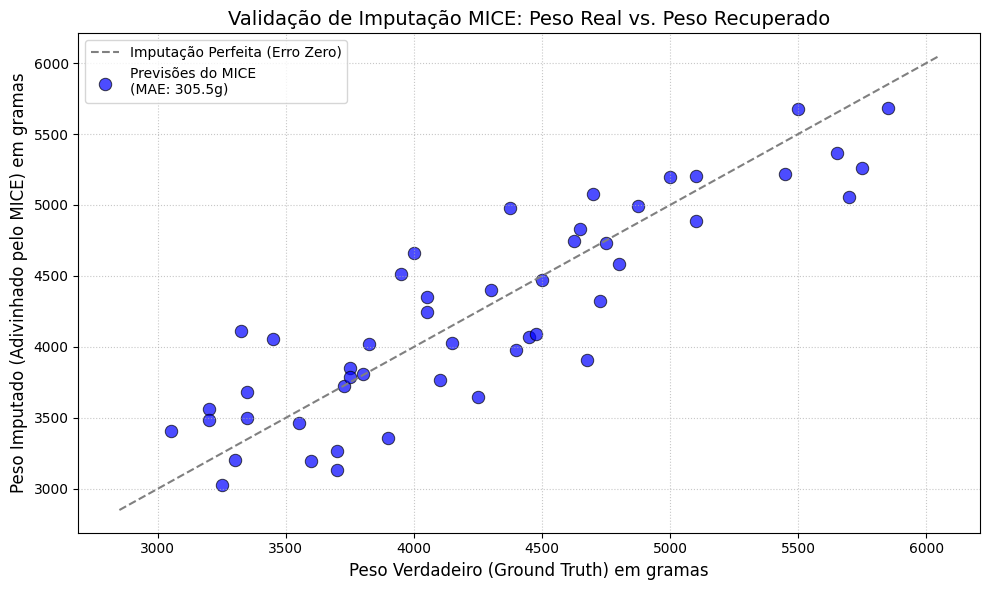

In [ ]:
# =====================================================================
#  Aplicando o MICE (IterativeImputer)
# =====================================================================
# O MICE vai usar o comprimento e profundidade do bico, além da asa,
# para criar uma regressão e "adivinhar" o peso faltante.
mice_imputer = IterativeImputer(random_state=42, max_iter=10)

# O imputer devolve uma matriz numpy, então a convertemos de volta para Pandas DataFrame
array_imputado = mice_imputer.fit_transform(df_corrupted)
df_imputed = pd.DataFrame(array_imputado, columns=colunas_numericas)

# =====================================================================
# Avaliação de Desempenho (Métrica de Erro)
# =====================================================================
# Nós NÃO avaliamos o dataset todo. Nós só calculamos o erro exatamente
# nas linhas onde nós apagamos os dados (usando a máscara).
valores_reais = df_clean.loc[mascara_falhas, 'body_mass_g']
valores_previstos = df_imputed.loc[mascara_falhas, 'body_mass_g']

# MAE (Mean Absolute Error): Em média, quantos gramas o modelo errou?
mae = mean_absolute_error(valores_reais, valores_previstos)

# Média ingênua (Baseline para comparar com o MICE)
# O que aconteceria se a gente só preenchesse com a média da coluna?
media_ingênua = df_corrupted['body_mass_g'].mean()
mae_ingenuo = mean_absolute_error(valores_reais, np.full(len(valores_reais), media_ingênua)) # recriamos o vetor com valores medios, np.full clona o valor

print("\n--- RESULTADOS DA IMPUTAÇÃO ---")
print(f"Erro Médio usando apenas a Média (Baseline): errou em ± {mae_ingenuo:.2f} gramas.")
print(f"Erro Médio Absoluto usando MICE: errou em ± {mae:.2f} gramas.")
print(f"Melhoria do MICE sobre a Média Simples: {((mae_ingenuo - mae) / mae_ingenuo) * 100:.1f}%")

# =====================================================================
# Visualização Gráfica do Resgate
# =====================================================================
plt.figure(figsize=(10, 6))

# Plotamos uma linha de referência (Previsão Perfeita)
limites = [valores_reais.min() - 200, valores_reais.max() + 200]
plt.plot(limites, limites, color='gray', linestyle='--', label='Imputação Perfeita (Erro Zero)')

# Plotamos os pontos (Real vs MICE)
sns.scatterplot(
    x=valores_reais,
    y=valores_previstos,
    color='blue',
    edgecolor='k',
    s=80,
    alpha=0.7,
    label=f'Previsões do MICE\n(MAE: {mae:.1f}g)'
)

plt.title('Validação de Imputação MICE: Peso Real vs. Peso Recuperado', fontsize=14)
plt.xlabel('Peso Verdadeiro (Ground Truth) em gramas', fontsize=12)
plt.ylabel('Peso Imputado (Adivinhado pelo MICE) em gramas', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()